# 01: Turning glucose into ethanol, in silico

**Goal:** use a computer model of *E. coli* to predict how much ethanol it can make from glucose, then search for gene deletions that make it produce more.

If any biology word here is new, the [README](../README.md) has a CS-flavoured glossary. The short version:

* A cell is a chemical factory. **Metabolites** (glucose, ATP, ethanol...) are converted by **reactions**, each catalysed by an **enzyme**, each enzyme encoded by one or more **genes**.
* A **metabolic model** is that factory's wiring diagram: every reaction, as a stoichiometric matrix `S`, plus which genes enable which reactions.
* **Flux balance analysis (FBA)** is a linear program: find reaction rates `v` with `S @ v == 0` (steady state, nothing piles up), within bounds, that maximise growth.

We start with `e_coli_core` (95 reactions, central metabolism only) because it is small enough to read. Then we repeat the analysis on the full genome-scale model.

In [1]:
import warnings
import matplotlib.pyplot as plt
import pandas as pd

from sugar2compound import (
    candidate_reactions, envelope, greedy_knockout_search, load_model,
    production_at_max_growth, set_glucose_medium,
)

pd.set_option("display.max_colwidth", 80)
warnings.filterwarnings("ignore", message="Solver status is 'infeasible'")

## 1. Look inside the model

In [2]:
model = load_model("e_coli_core")
print(f"{model.id}: {len(model.reactions)} reactions, {len(model.metabolites)} metabolites, {len(model.genes)} genes")

e_coli_core: 95 reactions, 72 metabolites, 137 genes


Each reaction has a formula and a **gene-protein-reaction rule (GPR)**: a boolean expression over genes.
`and` means the enzyme is a complex that needs *all* those genes; `or` means **isozymes**, alternative enzymes that each do the job.
That's why deleting one gene doesn't always remove a reaction.

In [3]:
for rxn_id in ["PGK", "PFK", "ALCD2x", "LDH_D"]:
    rxn = model.reactions.get_by_id(rxn_id)
    print(f"{rxn.id:8} {rxn.name}\n         {rxn.build_reaction_string(use_metabolite_names=True)}\n         genes: {rxn.gene_reaction_rule}\n")

PGK      phosphoglycerate kinase
         3-Phospho-D-glycerate + ATP <=> 3-Phospho-D-glyceroyl phosphate + ADP
         genes: b2926

PFK      phosphofructokinase
         ATP + D-Fructose 6-phosphate --> ADP + D-Fructose 1,6-bisphosphate + H+
         genes: b3916 or b1723

ALCD2x   alcohol dehydrogenase (ethanol)
         Ethanol + Nicotinamide adenine dinucleotide <=> Acetaldehyde + H+ + Nicotinamide adenine dinucleotide - reduced
         genes: b1478 or b0356 or b1241

LDH_D    D-lactate dehydrogenase
         D-Lactate + Nicotinamide adenine dinucleotide <=> H+ + Nicotinamide adenine dinucleotide - reduced + Pyruvate
         genes: b2133 or b1380



Metabolite ids end in a **compartment** tag: `_c` cytosol (inside the cell), `_e` extracellular (the growth medium), `_p` periplasm (between the two membranes; only in bigger models).
**Exchange reactions** (`EX_...`) are the model's I/O: negative flux = the cell takes it up, positive = it secretes it.
The **medium** is the set of exchanges allowed to run in reverse, with their maximum uptake rates (mmol per gram dry cell weight per hour).

In [4]:
model.medium

{'EX_co2_e': 1000.0,
 'EX_glc__D_e': 10.0,
 'EX_h_e': 1000.0,
 'EX_h2o_e': 1000.0,
 'EX_nh4_e': 1000.0,
 'EX_o2_e': 1000.0,
 'EX_pi_e': 1000.0}

## 2. Growing with oxygen

`model.optimize()` solves the LP. The objective value is the growth rate in 1/h (0.87/h ≈ doubling every 48 min, close to real *E. coli* on glucose).
`model.summary()` shows what goes in and comes out.

In [5]:
set_glucose_medium(model, glucose_uptake=10, aerobic=True)
model.summary()

Metabolite,Reaction,Flux,C-Number,C-Flux
glc__D_e,EX_glc__D_e,10,6,100.00%
nh4_e,EX_nh4_e,4.765,0,0.00%
o2_e,EX_o2_e,21.8,0,0.00%
pi_e,EX_pi_e,3.215,0,0.00%
Metabolite,Reaction,Flux,C-Number,C-Flux
co2_e,EX_co2_e,-22.81,1,100.00%
h2o_e,EX_h2o_e,-29.18,0,0.00%
h_e,EX_h_e,-17.53,0,0.00%


With oxygen, the cell burns glucose all the way to CO₂ (respiration) because that yields the most ATP. No ethanol.

## 3. Growing without oxygen

Without oxygen, the cell can't dump electrons onto O₂. Glycolysis produces NADH (a "charged battery" carrying electrons) that must be recharged back to NAD⁺, or glycolysis stalls.
**Fermentation** recycles NADH by dumping electrons onto carbon compounds instead: ethanol, lactate, succinate. Real *E. coli* does a "mixed acid fermentation".

In [6]:
set_glucose_medium(model, glucose_uptake=10, aerobic=False)
model.summary()

Metabolite,Reaction,Flux,C-Number,C-Flux
co2_e,EX_co2_e,0.3782,1,0.63%
glc__D_e,EX_glc__D_e,10,6,99.37%
h2o_e,EX_h2o_e,7.116,0,0.00%
nh4_e,EX_nh4_e,1.154,0,0.00%
pi_e,EX_pi_e,0.7786,0,0.00%
Metabolite,Reaction,Flux,C-Number,C-Flux
ac_e,EX_ac_e,-8.504,2,33.11%
etoh_e,EX_etoh_e,-8.279,2,32.23%
for_e,EX_for_e,-17.8,1,34.66%
h_e,EX_h_e,-30.55,0,0.00%


Growth drops a lot (fermentation makes ~2 ATP per glucose instead of ~20+), and now ethanol, acetate and formate come out.

## 4. How much ethanol, really?

Three numbers matter:

* **Theoretical max yield:** make the product the objective and ignore growth. Glucose (6 carbons) → 2 ethanol (2 carbons each) + 2 CO₂, so 2 mol/mol.
* **Max at optimal growth:** the cell grows as fast as possible. Several flux patterns can be equally optimal (the LP has alternative optima); this is the best one for us.
* **Guaranteed at optimal growth:** the *minimum* over those alternatives. Evolution optimises growth, not our yield, so this is the pessimistic number engineers use.

In [7]:
res = production_at_max_growth(model, "EX_etoh_e")
print(f"growth rate:               {res.growth:.3f} /h")
print(f"theoretical max yield:     {res.max_theoretical_yield:.2f} mol ethanol / mol glucose")
print(f"guaranteed yield @ growth: {res.guaranteed_yield:.2f} mol/mol")
print(f"best-case yield @ growth:  {res.target_flux_max / res.glucose_uptake:.2f} mol/mol")

growth rate:               0.212 /h
theoretical max yield:     2.00 mol ethanol / mol glucose
guaranteed yield @ growth: 0.83 mol/mol
best-case yield @ growth:  0.84 mol/mol


### The production envelope

For every growth rate, what range of ethanol output is possible? The shaded area is everything the model allows.
The top-left corner is "all carbon to product, no growth"; the right edge is "max growth".

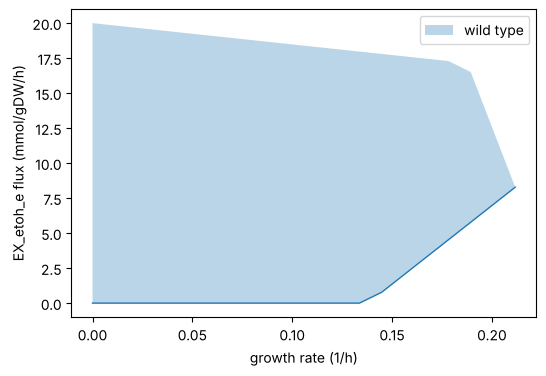

In [8]:
def plot_envelope(model, target, ax, label):
    env = envelope(model, target)
    biomass = env.columns[-1]  # the growth column is named after the biomass reaction
    ax.fill_between(env[biomass], env["flux_minimum"], env["flux_maximum"], alpha=0.3, label=label)
    ax.plot(env[biomass], env["flux_minimum"], lw=1)
    ax.set_xlabel("growth rate (1/h)")
    ax.set_ylabel(f"{target} flux (mmol/gDW/h)")

fig, ax = plt.subplots(figsize=(6, 4))
plot_envelope(model, "EX_etoh_e", ax, "wild type")
ax.legend();

## 5. Knockout search: make the cell *need* to produce ethanol

If we delete the reactions that compete with ethanol, the cell may only be able to grow by making ethanol. This is called **growth coupling**: the lower edge of the envelope lifts off zero at high growth, so the fastest-growing cells are also the best producers. That's valuable because over many generations, faster growers take over a culture.

`greedy_knockout_search` tries each candidate reaction deletion, keeps the best one, and repeats. It rejects designs growing below 0.05/h.

In [9]:
search = greedy_knockout_search(model, "EX_etoh_e", max_knockouts=3)
search.to_frame()

,knocked_out,genes,growth,guaranteed_yield
0,[],[],0.211663,0.825570
1,[PFL],"[b0902, b0903, b2579, b3114, b3951, b3952]",0.179985,1.652332
2,"[PFL, GLUDy]","[b0902, b0903, b1761, b2579, b3114, b3951, b3952]",0.170390,1.670513


PFL    pyruvate formate lyase                   genes: (b0902 and b3114) or (b0903 and b0902 and b2579) or (b0902 and b0903) or (b3951 and b3952)
GLUDy  glutamate dehydrogenase (NADP)           genes: b1761


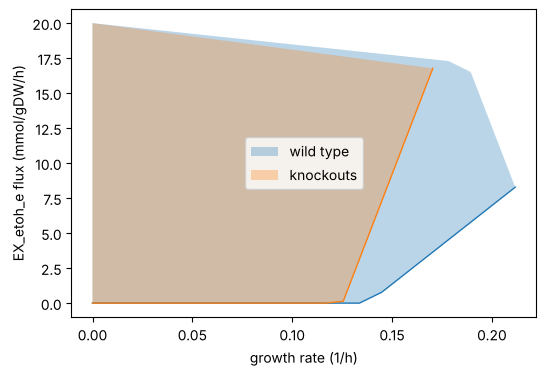

In [10]:
for rxn_id in search.steps[-1].knocked_out:
    rxn = model.reactions.get_by_id(rxn_id)
    print(f"{rxn.id:6} {rxn.name:40} genes: {rxn.gene_reaction_rule}")

fig, ax = plt.subplots(figsize=(6, 4))
plot_envelope(model, "EX_etoh_e", ax, "wild type")
with model:
    for rxn_id in search.steps[-1].knocked_out:
        model.reactions.get_by_id(rxn_id).knock_out()
    plot_envelope(model, "EX_etoh_e", ax, "knockouts")
ax.legend();

The first knockout, **PFL** (pyruvate formate lyase), roughly doubles the guaranteed yield. PFL is how fermenting *E. coli* splits pyruvate into acetyl-CoA and formate. With it gone, the model must route carbon a way that leaves ethanol as the best electron sink.

Notice the GPR on PFL: four alternative gene combinations. Removing PFL in the lab would mean deleting several genes (`pflB` b0903, `tdcE` b3114, `pflD` b3951...), not one. That's a reminder that **reaction knockouts are a simplification of gene knockouts**.

**Caveat:** this is a prediction. Real cells regulate genes (turning enzymes on or off), and FBA has no notion of that. Treat every result as a hypothesis to check against the literature, then the lab.

## 6. Scale up: the genome-scale model

`e_coli_core` leaves out amino acid synthesis, cofactors, membranes and more. Now the full model. `load_model("iML1515")` downloads the current reference model (1,516 genes) from BiGG; if you are offline it falls back to the bundled **iJO1366** (its 2011 predecessor, 1,367 genes).

In [11]:
big = load_model("iML1515")  # falls back to iJO1366 offline
set_glucose_medium(big, glucose_uptake=10, aerobic=False)
print(f"{big.id}: {len(big.reactions)} reactions, {len(big.genes)} genes")
res_big = production_at_max_growth(big, "EX_etoh_e")
print(f"growth {res_big.growth:.3f} /h, guaranteed ethanol yield {res_big.guaranteed_yield:.2f} mol/mol")

/tmp/claude-0/venv/lib/python3.13/site-packages/rich/live.py:260: UserWarning: install "ipywidgets" for Jupyter 
support
  warnings.warn('install "ipywidgets" for Jupyter support')

Could not fetch iML1515 from BiGG (The connection to the BiGG Models repository failed.); using bundled iJO1366 instead.


iJO1366: 2583 reactions, 1367 genes
growth 0.242 /h, guaranteed ethanol yield 0.80 mol/mol


With ~2,700 reactions, trying them all each round is slow, so `candidate_reactions` keeps reactions that carry flux in the wild type and skips transporters (whose gene assignments are often unreliable). This takes a minute or two.

In [12]:
candidates = candidate_reactions(big)
print(len(candidates), "candidate reactions")
big_search = greedy_knockout_search(big, "EX_etoh_e", max_knockouts=3, candidates=candidates)
big_search.to_frame()

334 candidate reactions


,knocked_out,genes,growth,guaranteed_yield
0,[],[],0.241502,0.803589
1,[PPC],[b3956],0.164978,1.000060
2,"[PPC, TKT2]","[b2465, b2935, b3956]",0.164081,1.023757
3,"[PPC, TKT2, ASPO6]","[b2465, b2574, b2935, b3956]",0.164041,1.023806


### Wait: is that first knockout real?

In the bundled iJO1366 the search picks **PPC** (PEP carboxylase, gene `ppc`) first. But a real `ppc` mutant **can't grow at all** on glucose minimal medium: PPC refills the TCA cycle's oxaloacetate, which the cell needs to build amino acids.
The model thinks it survives because it finds a bypass that the real cell doesn't use on glucose (gene regulation keeps it switched off, and FBA ignores regulation).

This is exactly the kind of model quirk [notebook 02](02_sanity_checks.ipynb) is designed to catch: its gene-essentiality check flags `ppc` as a mismatch. The fix is domain knowledge: exclude genes known to be essential and search again.

In [13]:
from sugar2compound.checks import KNOWN_ESSENTIAL

essential_rxns = {r.id for g in KNOWN_ESSENTIAL if g in big.genes for r in big.genes.get_by_id(g).reactions}
safe_candidates = [r for r in candidates if r not in essential_rxns]
safe_search = greedy_knockout_search(big, "EX_etoh_e", max_knockouts=3, candidates=safe_candidates)
safe_search.to_frame()

,knocked_out,genes,growth,guaranteed_yield
0,[],[],0.241502,0.803589
1,[TKT2],"[b2465, b2935]",0.239586,0.839748
2,"[TKT2, PGI]","[b2465, b2935, b4025]",0.213188,0.857423
3,"[TKT2, PGI, GLUDy]","[b1761, b2465, b2935, b4025]",0.194938,0.869297


Without the unrealistic PPC trick, single greedy knockouts give only small gains in the big model. The big model has many redundant routes, so removing one rarely forces a change; you often need two or three removed *together*, and greedy search, which only looks one step ahead, can't see that. Smarter algorithms (OptKnock, which encodes the search as a bilevel mixed-integer program) find these combinations.

## Exercises

1. Change the target to succinate (`EX_succ_e`) or D-lactate (`EX_lac__D_e`). Which knockouts does the search pick?
2. Run the knockout search aerobically. Why does it struggle to find growth-coupled ethanol designs?
3. Try known ethanol-strain deletions from the literature on the core model: `LDH_D` (lactate), `PTAr` (acetate), `FRD7` (succinate). Use `with model:` and `reaction.knock_out()`.
4. Write an exhaustive *pairs* search over the core model's candidates (`itertools.combinations`). Does it beat greedy?
5. Bigger stretch: *E. coli* can't make lycopene (the red pigment in tomatoes). Add the three heterologous reactions (CrtE, CrtB, CrtI from *Pantoea*) with `model.add_reactions`, using the model's `frdp_c` (farnesyl diphosphate) and `ipdp_c` (isopentenyl diphosphate), plus an exchange for lycopene, and simulate it.